# 멀티모달 RAG — 「아동·청소년 삶의 질 2025」 보도자료

- **자료**: 국가데이터처 국가통계연구원 보도자료 (2025.10.1, 16쪽) — `data/invest.pdf`
- **문제**: 이 자료의 핵심 수치 상당수가 **본문이 아니라 그래프 이미지 안에만** 있습니다 (예: OECD 국가별 순위, 지역별 시설 접근성).
  텍스트만 검색하는 RAG는 이런 질문에 "확인할 수 없다"고 답하거나 틀린 값을 지어냅니다.
- **구조**: ① 추출(텍스트·표·이미지) → ② 요약(검색용) → ③ 요약으로 검색하고 **원본**으로 답변 생성

> 실행 순서대로 위에서 아래로 실행합니다. API 키는 프로젝트 루트의 `.env` 에서 읽습니다.

## 0. 환경 준비

In [1]:
import os, sys, time, json, pickle
from pathlib import Path
from collections import Counter

from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.environ["UNSTRUCTURED_DISABLE_NOTICE"] = "1"

load_dotenv(PROJECT_ROOT / ".env")
assert os.getenv("OPENAI_API_KEY"), ".env 에 OPENAI_API_KEY 가 없습니다."
print("OPENAI_API_KEY 로드:", "OK (값은 출력하지 않음)")

PDF_PATH = PROJECT_ROOT / "data" / "invest.pdf"
FIG_DIR = PROJECT_ROOT / "figures"
DOCS_DIR = PROJECT_ROOT / "docs"
DOCS_DIR.mkdir(exist_ok=True)
print("PDF:", PDF_PATH.relative_to(PROJECT_ROOT), "| 존재:", PDF_PATH.exists())

OPENAI_API_KEY 로드: OK (값은 출력하지 않음)
PDF: data\invest.pdf | 존재: True


## 1단계. 데이터 추출 (텍스트 · 표 · 이미지)

| 선택 | 이유 |
| --- | --- |
| `unstructured` `hi_res` | 레이아웃 모델로 표·그림 **위치**를 찾아 그림을 `figures/` 에 잘라 저장 |
| 표 내용은 PyMuPDF로 읽기 | Tesseract 한국어 데이터가 없으면 표 OCR이 `Apsja) oy W6` 처럼 깨짐 → 표 영역 좌표만 쓰고 글자는 PDF 텍스트 레이어에서 읽음 |
| 그림 속 OCR 잡음 제거 | `Image` 요소의 OCR 텍스트(깨진 영문)를 본문에서 빼고 `chunk_by_title` 로 다시 묶음 |
| 그림 제목 연결 | 잘린 그래프에는 제목이 없음 → 바로 위의 `< 제목 >` 을 찾아 요약 단계에 함께 전달 |

In [2]:
from extract import extract_pdf_elements, categorize_elements, split_texts, select_figures, figure_captions

start = time.time()
raw_elements = extract_pdf_elements(PDF_PATH, FIG_DIR)
print(f"추출 완료 — {time.time() - start:.0f}초, 요소 {len(raw_elements)}개")
for kind, n in Counter(type(e).__name__ for e in raw_elements).most_common():
    print(f"  {kind:15s} {n}")

No languages specified, defaulting to English.


Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 367/367 [00:00<00:00, 6007.11it/s]

추출 완료 — 82초, 요소 524개
  Image           275
  Text            114
  ListItem        49
  NarrativeText   39
  Title           20
  FigureCaption   18
  Table           7
  Header          2


In [3]:
texts, tables = categorize_elements(raw_elements, PDF_PATH)
chunks = split_texts(texts, chunk_size=2000, chunk_overlap=200)

all_images = sorted(FIG_DIR.glob("figure-*.jpg"))
figures = select_figures(FIG_DIR)          # 로고·작은 조각 제외
captions = figure_captions(raw_elements, PDF_PATH)

print(f"텍스트 블록 {len(texts)}개 → 분할 후 청크 {len(chunks)}개")
print(f"표 {len(tables)}개")
print(f"이미지: figures/ 에 {len(all_images)}개 저장 → 검색에 쓸 그래프 {len(figures)}개 선별")
print()
for f in figures:
    print(f"  {f.name:20s} {captions.get(f.name, '(제목 없음: 지표 체계도)')}")

텍스트 블록 5개 → 분할 후 청크 11개
표 5개
이미지: figures/ 에 275개 저장 → 검색에 쓸 그래프 26개 선별

  figure-3-235.jpg     (제목 없음: 지표 체계도)
  figure-4-237.jpg     아동 ‧ 청소년 인구 비율 (2000~2040)
  figure-4-238.jpg     이주배경 아동 ‧ 청소년 인구 비율 (2017~2025)
  figure-4-239.jpg     한부모 양육 비율 (2016~2024)
  figure-4-240.jpg     아동 가구의 맞벌이 비율 (2016~2024)
  figure-5-241.jpg     상대적 빈곤율 (2011~2023)
  figure-5-242.jpg     OECD 국가 아동의 상대적 빈곤율 (2022)
  figure-6-245.jpg     지역규모별 거주지역 편의성 (2023)
  figure-7-246.jpg     스트레스 인지율 (2005~2024)
  figure-7-248.jpg     범불안장애 경험률 (2020~2024)
  figure-8-250.jpg     성별 비만율 (2016~2024)
  figure-8-251.jpg     학교급별 비만율 (2016~2024)
  figure-8-254.jpg     영양결핍률 (2001~2023)
  figure-9-255.jpg     학습시간 (2014~2024)
  figure-9-256.jpg     학교급별 사교육 참여율 (2007~2024)
  figure-10-257.jpg    주관적 학업성취도 (2014~2023)
  figure-10-258.jpg    성 및 지역별 주관적 학업성취도 (2023)
  figure-10-259.jpg    학교생활 만족도 (2014~2023)
  figure-10-260.jpg    성 및 지역별 학교생활 만족도 (2023)
  figure-11-261.jpg    연령별 여가생활 만족도 (2017~2023)
  figure-12-262

In [4]:
print("=" * 70); print("[표 예시]"); print(tables[2])
print("=" * 70); print("[텍스트 청크 예시] 앞 400자"); print(chunks[3][:400])

[표 예시]
[12쪽 표]
중학생( . . ), 등학생( . . )


 < 피해유형별 또래폭력 피해 경험률 (2022~2024) >
 (단위: %)
 학교 안과 밖 온라인 공간
 피해
 언어 신체 언어 경험률 갈취 위협따돌림심부름감금 갈취 위협따돌림망신 폭력 폭력 폭력

2022 16.3 10.6 6.0 2.1 2.8 1.6 0.5 - 7.3 1.4 1.7 1.0 -

2024 22.6 16.0 7.5 2.3 3.5 2.6 1.0 0.9 9.1 2.4 2.1 1.1 2.2

주 ) (초등학 학년 등학생대상) 전체경험률 제시된유형중한가지라 경험해본적이있는응답자비율임
[텍스트 청크 예시] 앞 400자
□ 아동‧청소년(0~18세)이 있는 가구의 최저주거기준 미달 가구 비율은 ’23년 2.2%로 전체 일반가구(3.6%)보다 낮은 편임(보고서 38쪽)

ㅇ ’22년(1.9%)에 비해 소폭 증가하였으나 ’17년(4.4%) 이후 감소 추세임

< 최저주거기준 미달 가구 비율 (2017~2023) >

(단위: %)

= 77a 0~18A] Of S0| BSE Ftp eI zx 7 ae

7k

7 = OS LT

출처: 국토교통부, ｢주거실태조사」 각 연도 원자료 분석

□ 거주지역 내에서 이용 가능한 편의시설인 문화체육시설, 의료기관, 교육시설, 대중교통 등의 접근성은 도시와 농어촌 간의 차이가 큼(보고서 36~37쪽)

ㅇ 의료기관이나 자연환경을 제외하면 대도시와 중소도시는 편의시설 접근성이 비슷한 수준임




figure-5-242.jpg → OECD 국가 아동의 상대적 빈곤율 (2022)


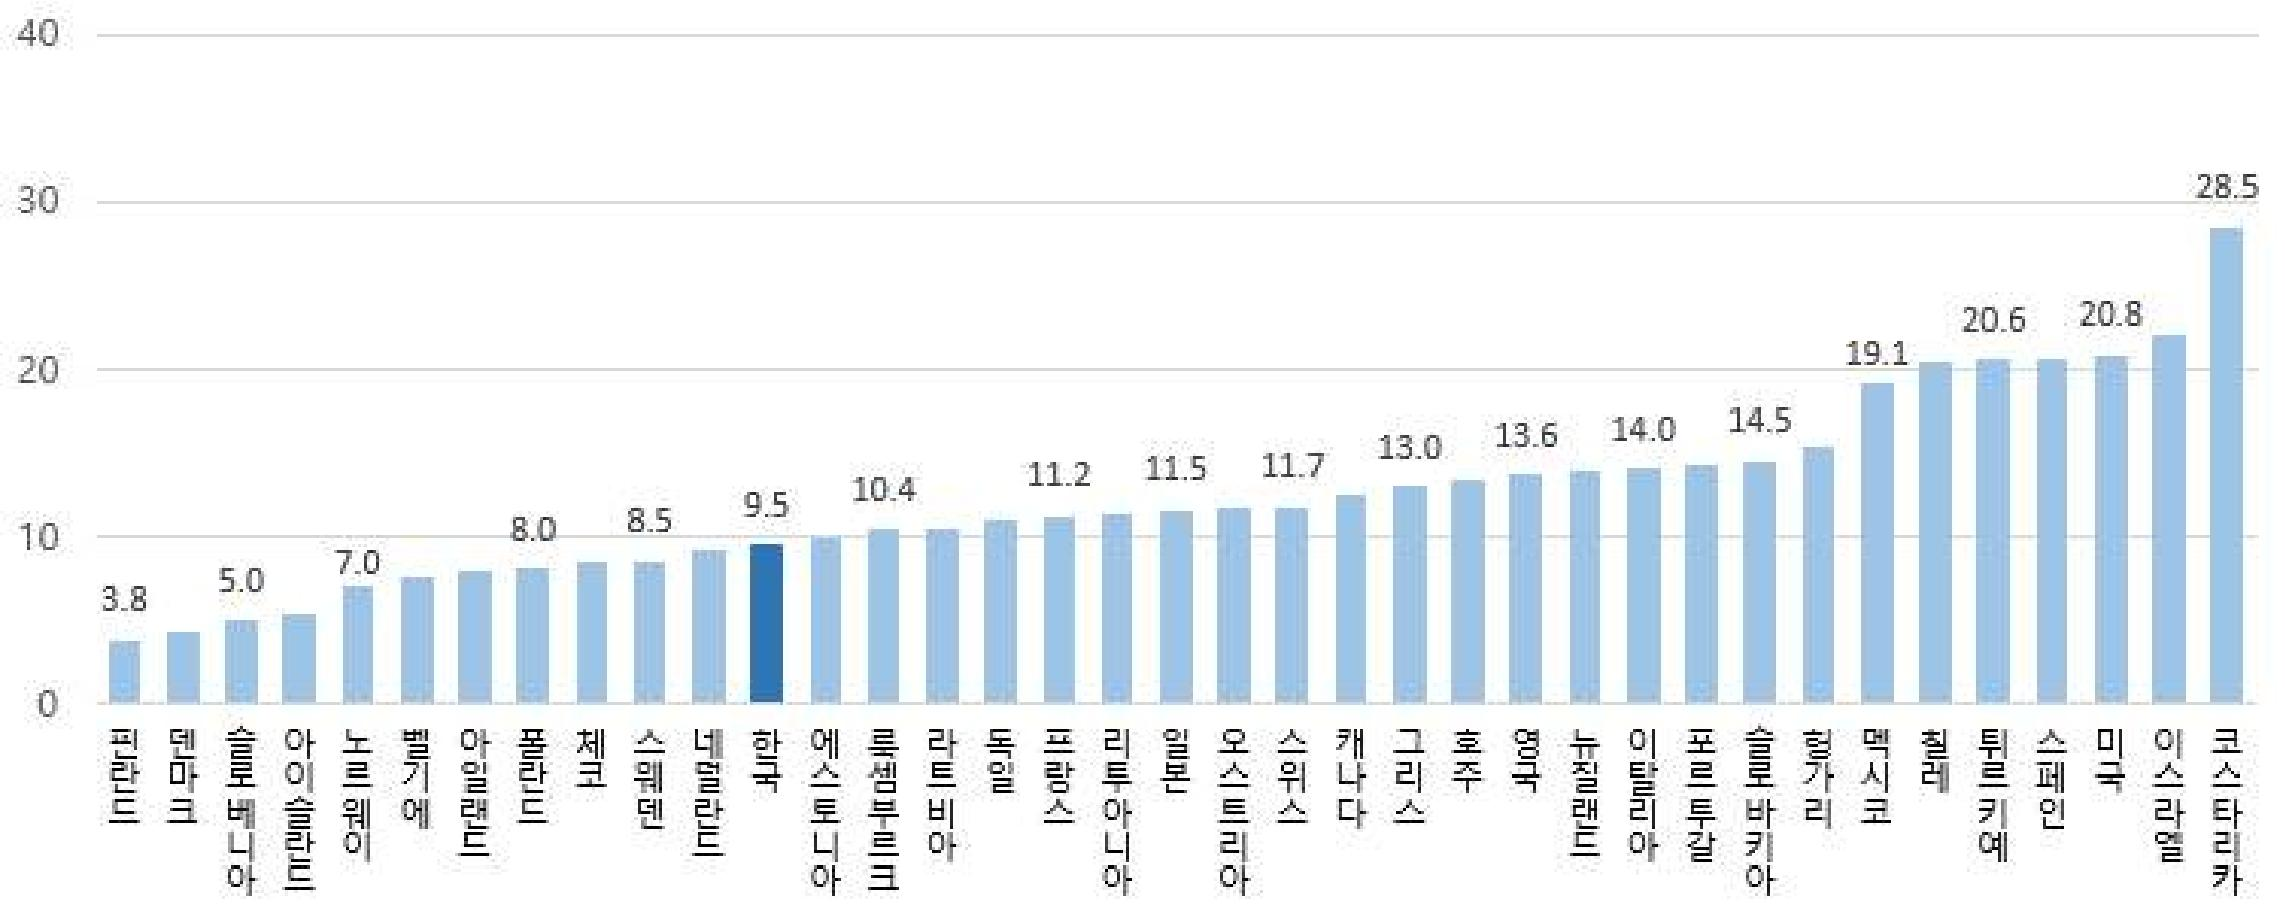

figure-6-245.jpg → 지역규모별 거주지역 편의성 (2023)


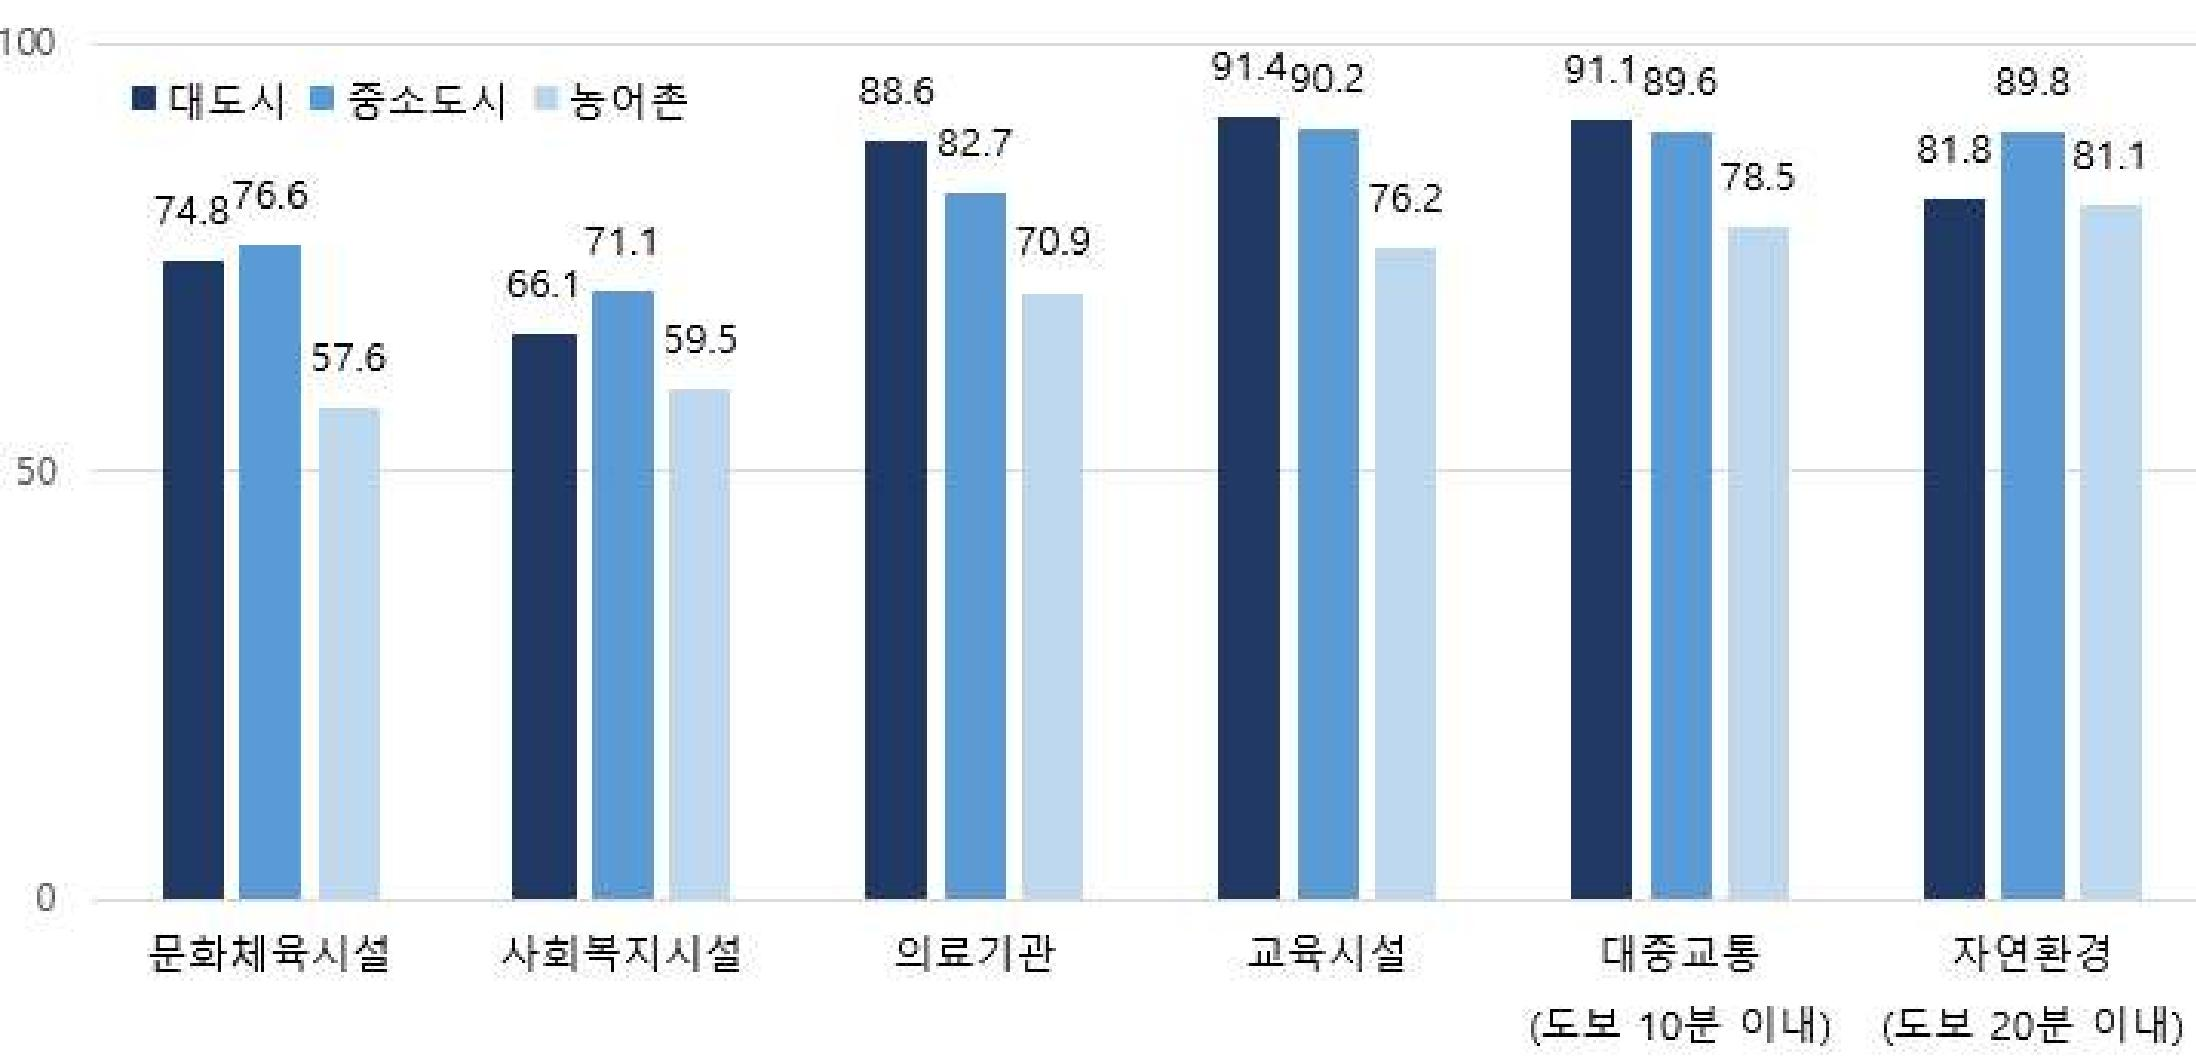

In [5]:
from IPython.display import Image, display

for name in ["figure-5-242.jpg", "figure-6-245.jpg"]:
    print(name, "→", captions.get(name))
    display(Image(filename=str(FIG_DIR / name), width=650))

## 2단계. 요약 생성 (검색용)

- 텍스트·표: `gpt-4o-mini` + **한국어 프롬프트** — 질문도 한국어로 들어오므로 요약도 한국어여야 임베딩 공간에서 가깝게 매칭됨
- 이미지: `gpt-4o-mini`(비전) + **영어 지시문 / 한국어 출력** — 지시는 모델이 가장 잘 따르는 영어로, 결과는 검색 언어인 한국어로.
  문서에 인쇄된 그래프 제목을 프롬프트에 넣어 "연도별 지표 변화" 같은 뭉뚱그린 요약을 막음

In [6]:
from summarize import generate_text_summaries, generate_img_summaries

start = time.time()
text_summaries, table_summaries = generate_text_summaries(chunks, tables)
print(f"텍스트·표 요약 — {time.time() - start:.0f}초 | 텍스트 {len(text_summaries)}개, 표 {len(table_summaries)}개")

start = time.time()
img_base64_list, image_summaries = generate_img_summaries(figures, captions)
print(f"이미지 요약 — {time.time() - start:.0f}초 | 이미지 {len(image_summaries)}개")

텍스트·표 요약 — 13초 | 텍스트 11개, 표 5개


이미지 요약 — 21초 | 이미지 26개


In [7]:
print("[원본 표]"); print(tables[3]); print()
print("[표 요약]"); print(table_summaries[3]); print()
print("[텍스트 요약 예시]"); print(text_summaries[3])

[원본 표]
[13쪽 표]
< 흡연율 및 음주율 (2019~2024) >
 (단위: %)

 2019 2020 2021 2022 2023 2024

흡연율 7.3 4.8 5.2 5.4 5.1 4.5

음주율 15.0 10.7 10.7 13.0 11.1 9.7

주: 1) 흡연율: (중‧고등학생대상) 최근30일동안한번이라도흡연(일반담배전자담배포함) 했다고응답한비율임

[표 요약]
2019년 중고등학생의 흡연율은 7.3%에서 2024년에는 4.5%로 감소하였고, 2023년에는 5.1%로 소폭 증가한 후 다시 감소했습니다. 음주율은 2019년 15.0%에서 2024년 9.7%로 감소하였으며, 2023년에는 11.1%로 증가한 후 다시 감소했습니다. 전체적으로 두 지표 모두 감소 추세를 보이고 있습니다.

[텍스트 요약 예시]
2023년 아동·청소년(0~18세)이 있는 가구의 최저주거기준 미달 가구 비율은 2.2%로, 전체 일반가구의 3.6%보다 낮으며, 2022년의 1.9%에 비해 소폭 증가하였으나 2017년의 4.4% 이후 감소 추세를 보이고 있다. 또한, 2023년 청소년의 스트레스 인지율은 37.3%에서 2024년 42.3%로 5.0%p 증가하였고, 여학생의 스트레스 인지율은 49.9%로 남학생의 35.2%보다 14.7%p 높다. 범불안장애 경험률은 2023년 12.6%에서 2024년 14.1%로 1.5%p 증가하였으며, 여학생의 경험률은 18.0%로 남학생의 10.3%보다 7.7%p 높다.


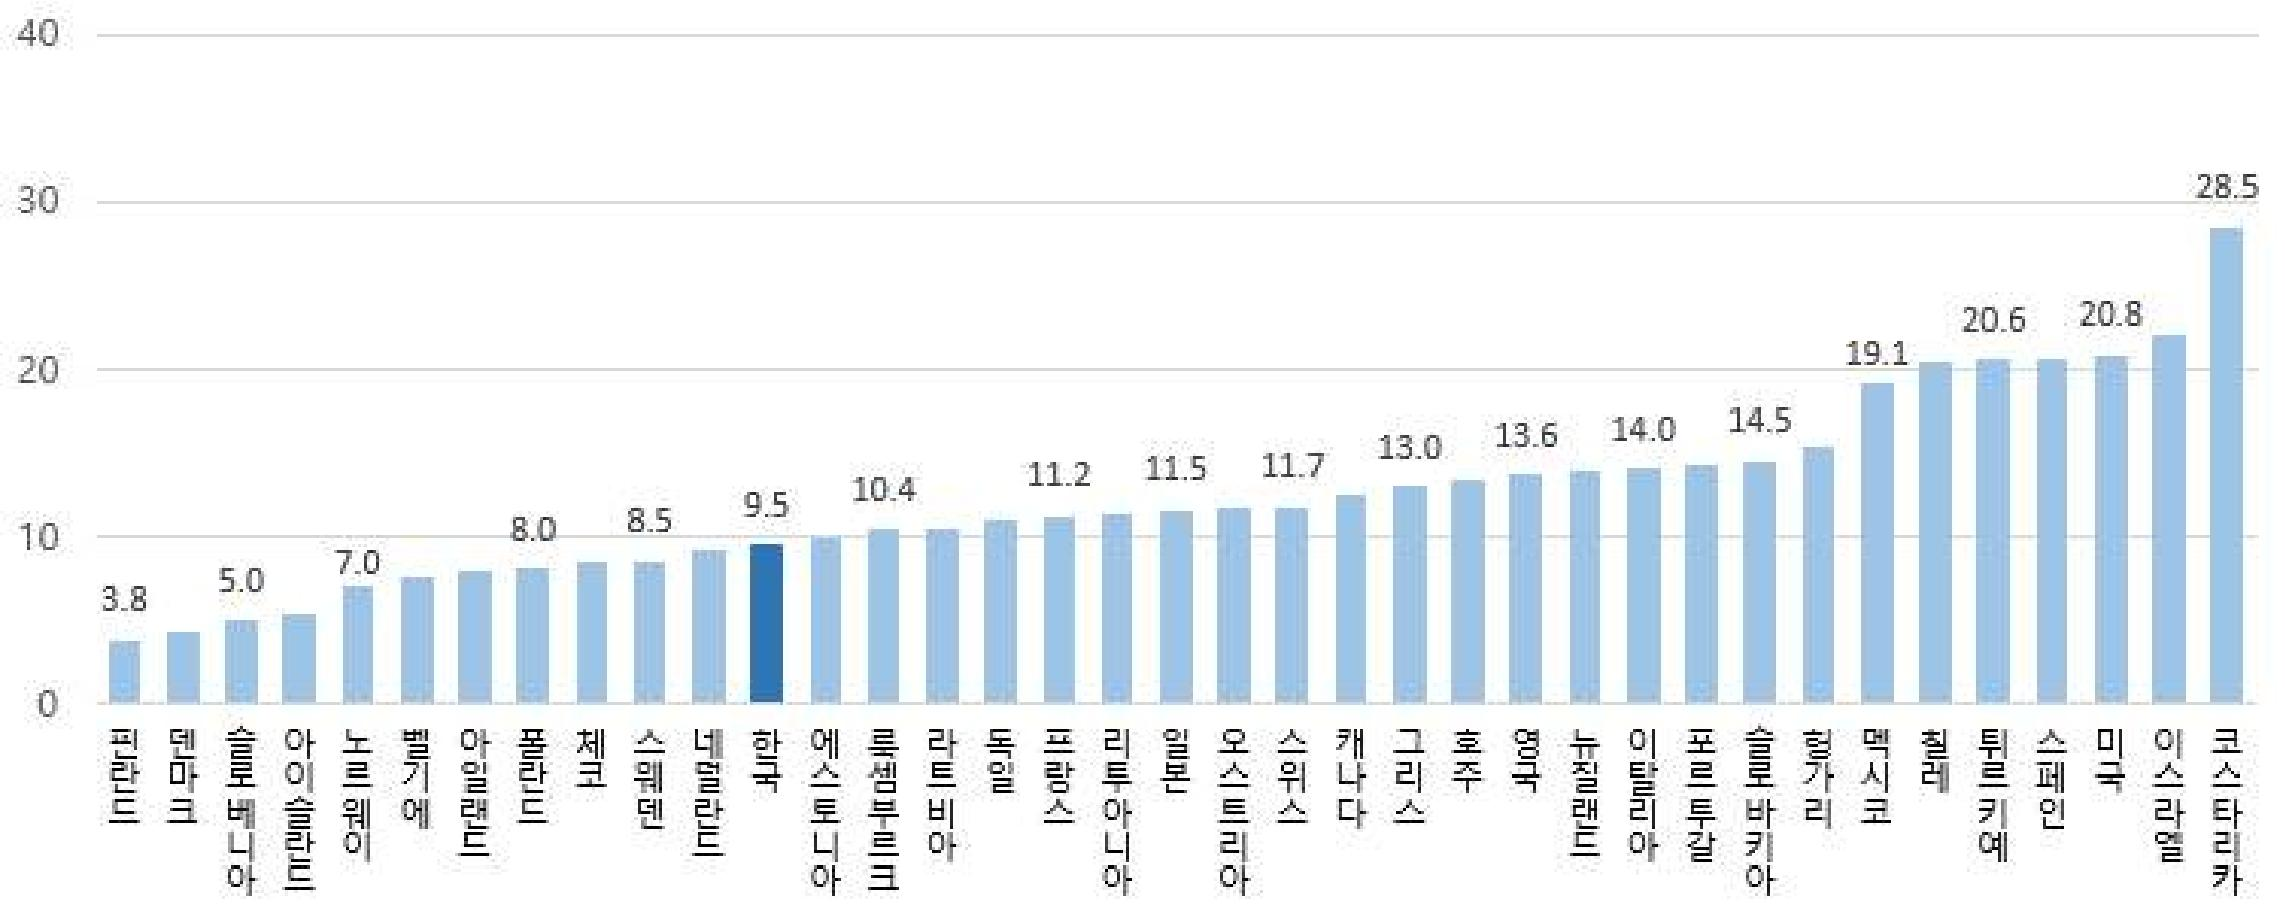

"OECD 국가 아동의 상대적 빈곤율 (2022)"

이 차트는 OECD 국가의 아동 상대적 빈곤율을 나타내는 세로 막대 그래프입니다. X축은 국가를, Y축은 빈곤율(%)을 나타내며, 최대값은 40%입니다. 차트에서 가장 낮은 빈곤율은 핀란드의 3.8%로 시작하여, 덴마크(5.0%), 슬로베니아(7.0%) 등이 뒤를 잇습니다. 한국은 9.5%로 중간 정도의 위치에 있으며, 가장 높은 빈곤율은 코스타리카의 28.5%입니다. 전반적으로, 아동 빈곤율은 국가에 따라 큰 차이를 보이며, 일부 국가에서는 상대적으로 높은 빈곤율이 나타납니다.


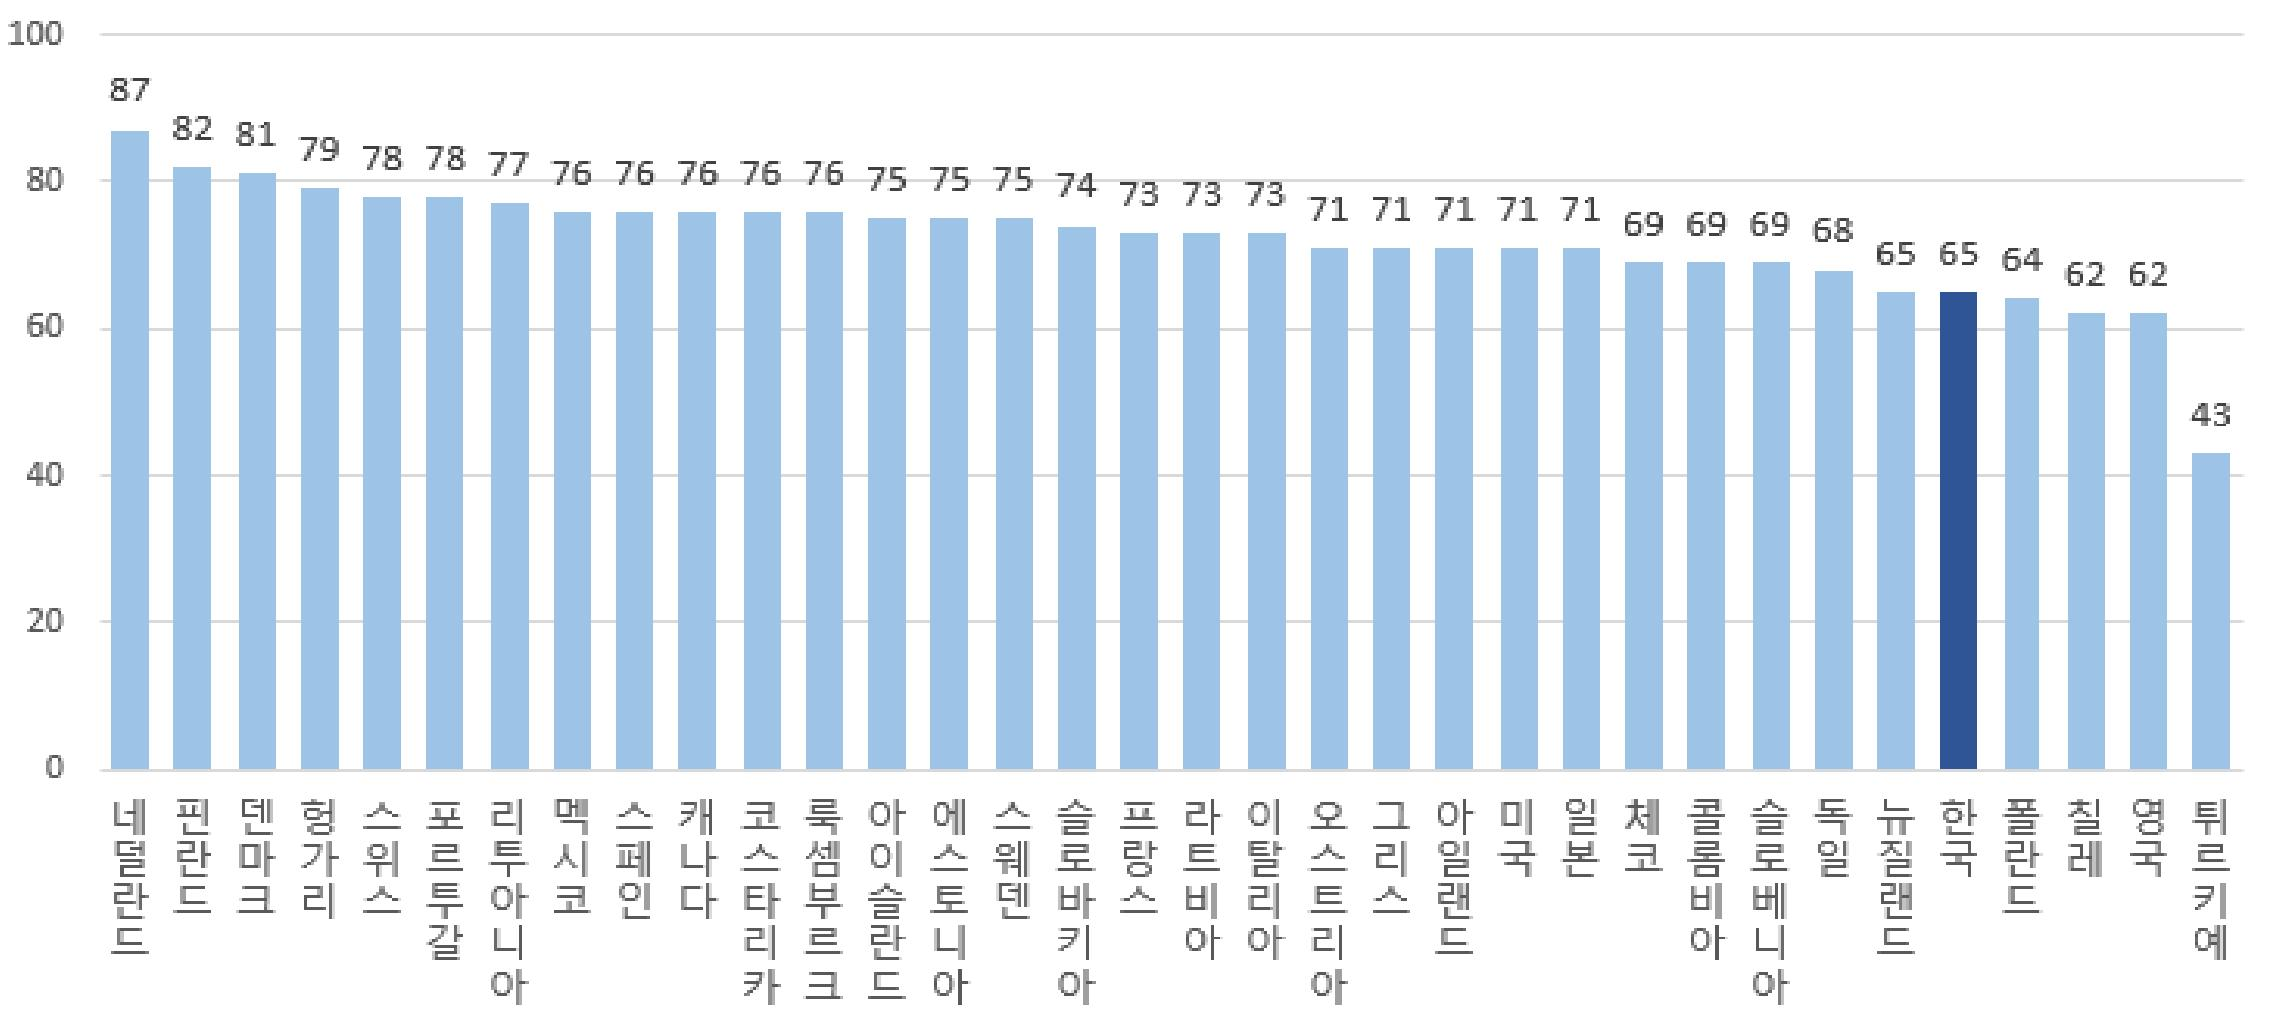

OECD 국가의 삶의 만족도 (2022)

이 차트는 막대 그래프 형태로, 각 국가의 삶의 만족도를 나타냅니다. Y축은 만족도 점수를 나타내며, 0에서 100까지의 범위를 가지고 있습니다. 차트에는 네덜란드(87), 덴마크(82), 핀란드(81) 등 여러 국가가 포함되어 있으며, 한국은 65점으로 중간 정도의 위치에 있습니다. 가장 낮은 점수는 튀르키예(43)로 나타났습니다. 전반적으로 북유럽 국가들이 높은 만족도를 보이는 반면, 튀르키예는 가장 낮은 만족도를 기록했습니다.


In [8]:
# 요약 품질 검증: 그림과 요약을 나란히 놓고 눈으로 대조
for name in ["figure-5-242.jpg", "figure-16-275.jpg"]:
    i = [f.name for f in figures].index(name)
    display(Image(filename=str(figures[i]), width=600))
    print(image_summaries[i]); print("=" * 70)

In [9]:
import tiktoken
enc = tiktoken.encoding_for_model("gpt-4o-mini")
in_tok = sum(len(enc.encode(t)) for t in chunks + tables)
out_tok = sum(len(enc.encode(s)) for s in text_summaries + table_summaries + image_summaries)
print(f"텍스트·표 요약 입력 ≈ {in_tok:,} 토큰 / 전체 요약 출력 ≈ {out_tok:,} 토큰 / 이미지 {len(figures)}장")

out_dir = PROJECT_ROOT / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
with open(out_dir / "summaries.pkl", "wb") as f:
    pickle.dump({"chunks": chunks, "tables": tables, "text_summaries": text_summaries,
                 "table_summaries": table_summaries, "image_summaries": image_summaries,
                 "img_base64_list": img_base64_list, "figure_names": [p.name for p in figures]}, f)
print("저장:", (out_dir / "summaries.pkl").relative_to(PROJECT_ROOT))

텍스트·표 요약 입력 ≈ 8,668 토큰 / 전체 요약 출력 ≈ 7,926 토큰 / 이미지 26장
저장: data\processed\summaries.pkl


## 3단계. 검색과 답변 — 요약으로 찾고, 원본으로 답한다

- **Chroma**(벡터DB)에는 요약문 임베딩만, **InMemoryStore**(docstore)에는 원본(텍스트·표·이미지 base64)을 넣고 `doc_id` 로 연결 → `MultiVectorRetriever`
- 답변 모델 `gpt-5-mini`: 검색된 **원본 그래프 이미지**를 직접 보고 수치를 읽음 (사전 테스트에서 `gpt-4o-mini`는 OECD 그래프 최댓값 국가를 '멕시코'로 잘못 읽음)
- 비교군(Before): 본문 텍스트 청크만 임베딩한 일반 텍스트 RAG (같은 답변 모델·프롬프트·k=5)

In [10]:
from retriever import create_multi_vector_retriever, create_text_retriever, build_rag_chain, source_types

mm_retriever = create_multi_vector_retriever(
    text_summaries, chunks, table_summaries, tables,
    image_summaries, img_base64_list, [p.name for p in figures], k=5,
)
text_retriever = create_text_retriever(chunks, k=5)

# 같은 질문에 대해: 벡터DB에서 맞은 '요약' vs 실제로 돌려받는 '원본'
q = "농어촌 지역 아동의 문화체육시설 접근성"
hit = mm_retriever.vectorstore.similarity_search(q, k=1)[0]
raw = mm_retriever.invoke(q)
print("[벡터DB에서 찾은 요약]", hit.metadata["type"], hit.metadata["source"]); print(hit.page_content[:200]); print()
print("[retriever가 돌려준 원본]", source_types(raw))
print("이미지 원본은 base64 길이:", [len(d.page_content) for d in raw if d.metadata["type"] == "image"])

[벡터DB에서 찾은 요약] image figure-6-245.jpg
지역규모별 거주지역 편의성 (2023)

이 차트는 세 가지 지역 규모(대도시, 중소도시, 농어촌)에 따른 거주지역의 편의성을 비교한 막대 그래프입니다. X축은 시설 종류로, 문화체육시설, 사회복지시설, 의료기관, 교육시설, 대중교통, 자연환경이 표시되어 있습니다. Y축은 편의성 점수로, 0에서 100까지의 범위를 가집니다. 대도시는 모든 항목에서 가장 높

[retriever가 돌려준 원본] image(figure-6-245.jpg), image(figure-10-260.jpg), image(figure-4-237.jpg), text(text-6), image(figure-10-258.jpg)
이미지 원본은 base64 길이: [218724, 54544, 60848, 56060]


In [11]:
QUESTIONS = [
    "OECD 국가 아동의 상대적 빈곤율(2022)에서 빈곤율이 가장 높은 나라는 어디이고 몇 %인가요? 한국과 비교해 주세요.",
    "2023년 농어촌 지역 아동의 문화체육시설 접근성은 대도시와 비교해 몇 %인가요?",
    "2021년 중·고등학생의 흡연율과 음주율은 각각 몇 %인가요?",
    "OECD 국가의 15세 청소년 삶의 만족도(2022)에서 가장 높은 나라와 가장 낮은 나라는 어디이며, 한국은 몇 %인가요?",
    "2025년 아동·청소년 인구는 전체 인구의 몇 %이고, 이주배경 아동·청소년 비율은 몇 %인가요?",
]

mm_chain = build_rag_chain(mm_retriever)
text_chain = build_rag_chain(text_retriever)

results = []
start = time.time()
for q in QUESTIONS:
    mm, tx = mm_chain.invoke(q), text_chain.invoke(q)
    results.append({
        "question": q,
        "multimodal_answer": mm["answer"],
        "multimodal_sources": source_types(mm["docs"]),
        "text_answer": tx["answer"],
        "text_sources": source_types(tx["docs"]),
    })
print(f"질의 {len(QUESTIONS)}건 × 2개 체인 — {time.time() - start:.0f}초")

질의 5건 × 2개 체인 — 35초


In [12]:
for i, r in enumerate(results, 1):
    print(f"Q{i}. {r['question']}")
    print(f"  ▶ 멀티모달 RAG: {r['multimodal_answer']}")
    print(f"     근거: {r['multimodal_sources']}")
    print(f"  ▷ 텍스트 RAG : {r['text_answer']}")
    print("-" * 90)

Q1. OECD 국가 아동의 상대적 빈곤율(2022)에서 빈곤율이 가장 높은 나라는 어디이고 몇 %인가요? 한국과 비교해 주세요.
  ▶ 멀티모달 RAG: OECD 국가 중 아동 상대적 빈곤율이 가장 높은 나라는 코스타리카로 28.5%입니다(그래프 이미지에서 읽은 값임). 한국의 아동 상대적 빈곤율은 2022년 기준 9.5%입니다. 수치로 비교하면 코스타리카(28.5%)가 한국(9.5%)보다 높습니다.
     근거: image(figure-5-242.jpg), image(figure-16-275.jpg), text(text-10), table(table-4), text(text-2)
  ▷ 텍스트 RAG : 자료에서 OECD 국가 중 아동의 상대적 빈곤율(2022)이 가장 높은 나라와 그 수치는 확인할 수 없습니다. 다만 우리나라 아동‧청소년(0~17세)의 상대적 빈곤율은 ’22년 기준 9.5%이며 OECD 37개국 중 12위입니다.
------------------------------------------------------------------------------------------
Q2. 2023년 농어촌 지역 아동의 문화체육시설 접근성은 대도시와 비교해 몇 %인가요?
  ▶ 멀티모달 RAG: 그래프 이미지에서 읽은 값에 따르면 2023년 농어촌 지역 아동의 문화체육시설 접근성은 57.6%이고 대도시는 74.8%입니다. 따라서 농어촌(57.6%)이 대도시(74.8%)보다 낮습니다.
     근거: text(text-6), image(figure-10-260.jpg), image(figure-6-245.jpg), image(figure-10-258.jpg), table(table-4)
  ▷ 텍스트 RAG : 자료에 따르면 2023년 농어촌 지역의 문화체육시설 접근성은 대도시에 비해 17%p 이상 낮습니다. 따라서 농어촌의 접근성이 대도시보다 낮습니다.
-----------------------------------------------------

## Before / After 비교 (텍스트 RAG vs 멀티모달 RAG)

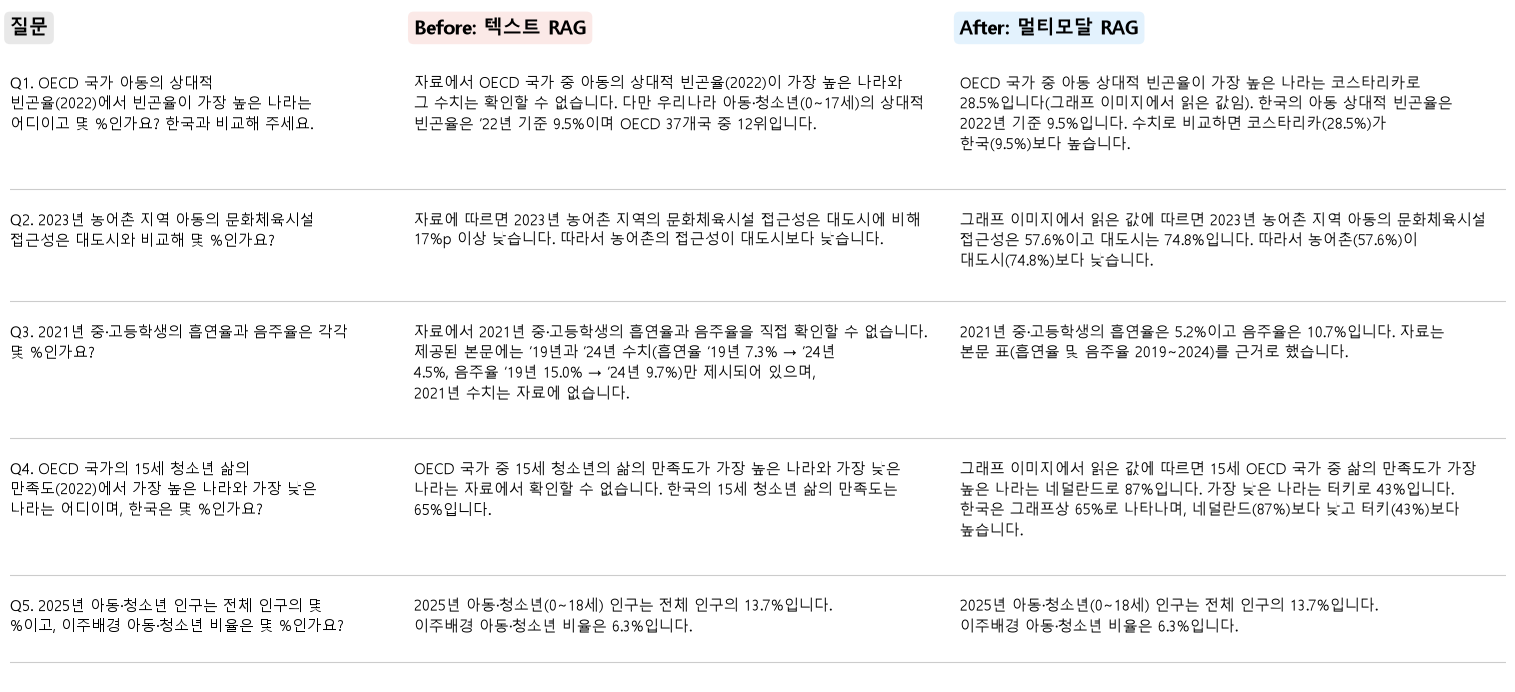

In [13]:
import textwrap
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

def wrap(s, width):
    s = s.replace("\n", " ").replace("‧", "·")
    return "\n".join(textwrap.wrap(s, width))

cols = [("질문", 0.0, 30, "#e8e8e8"), ("Before: 텍스트 RAG", 0.27, 44, "#fbe9e7"), ("After: 멀티모달 RAG", 0.635, 44, "#e3f2fd")]
rows = []
for i, r in enumerate(results, 1):
    cells_ = [f"Q{i}. " + r["question"], r["text_answer"], r["multimodal_answer"]]
    wrapped = [wrap(c, w) for c, (_, _, w, _) in zip(cells_, cols)]
    rows.append((wrapped, max(w.count("\n") + 1 for w in wrapped)))
total = sum(n + 1.5 for _, n in rows) + 2.5          # 줄 단위 높이

fig, ax = plt.subplots(figsize=(16, 0.26 * total))
ax.set_xlim(0, 1); ax.set_ylim(total, 0); ax.axis("off")
for title, x, _, color in cols:
    ax.text(x, 0.3, title, fontsize=14, weight="bold", va="top",
            bbox=dict(boxstyle="round", fc=color, ec="none"))
y = 2.5
for wrapped, n in rows:
    for w, (_, x, _, _) in zip(wrapped, cols):
        ax.text(x, y, w, fontsize=10.5, va="top", linespacing=1.4)
    y += n + 1.5
    ax.axhline(y - 0.8, color="#cccccc", lw=0.8)
plt.tight_layout()
plt.savefig(DOCS_DIR / "before_after.png", dpi=110, bbox_inches="tight")
plt.show()

In [14]:
with open(DOCS_DIR / "qa_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("저장:", "docs/before_after.png, docs/qa_results.json")

저장: docs/before_after.png, docs/qa_results.json


## 정리

- 텍스트 RAG는 **본문에 문장으로 적힌 수치**(Q5)만 맞히고, 표(Q3)·그래프(Q1, Q2, Q4)에만 있는 값은 "확인할 수 없다"고 답함
- 멀티모달 RAG는 표 요약/그래프 요약으로 해당 원본을 **찾아낸 뒤**, 원본 표 텍스트와 그래프 이미지를 LLM에 그대로 넘겨 정확한 수치로 답함
- 요약은 '찾기 위한 색인', 답변은 '원본'으로 — 요약 과정에서 잃어버린 세부 수치를 답변 단계에서 되살릴 수 있음